# CHƯƠNG 4: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (làm lại)



## 0. Khởi tạo, nạp dữ liệu, kiểm tra

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 9.5; plt.rcParams['figure.titlesize'] = 11

DATA_DIR = os.environ.get('DATA_DIR', '../Datasets')
RAW_DIR  = os.environ.get('RAW_DIR',  '../Datasets')

A = pd.read_csv(os.path.join(DATA_DIR, 'group_a_survival.csv'), parse_dates=['install_date', 'first_active', 'last_active'])
B = pd.read_csv(os.path.join(DATA_DIR, 'group_b_landmark_survival.csv'), parse_dates=['install_date', 'first_active', 'last_active'])

COH = A[A.verified_new == 1].copy()
OLD = A[A.is_new == 0].copy()

def km(df, tcol='T', ecol='event', entry=False):
    f = KaplanMeierFitter()
    f.fit(df[tcol], df[ecol], entry=df.entry if entry else None)
    return f

def km_row(df, label, tcol='T', ecol='event', entry=False, pts=(7, 14, 30, 60)):
    f = km(df, tcol, ecol, entry=entry); n = len(df); ev = int(df[ecol].sum())
    r = {'Nhóm': label, 'N': n, 'Sự kiện': ev, 'Tỉ lệ churn': round(ev / n * 100, 1), 'Trung vị (ngày)': f.median_survival_time_}
    for p in pts: r[f'S({p})'] = round(float(f.predict(p)), 3)
    return r

def holm(pvals):
    pvals = np.asarray(pvals)
    n = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(n, float)
    cummax = 0.0
    for i, idx in enumerate(order):
        val = pvals[idx] * (n - i)
        cummax = max(cummax, val)
        adj[idx] = min(1.0, cummax)
    return adj

def save_tab(df, name): df.to_csv(os.path.join(OUT_TAB, name + '.csv'))
MIN_AT_RISK = 30
print(f'Nạp dữ liệu thành công. Nhóm A: {len(A)} | Cohort verified: {len(COH)} | Cài cũ: {len(OLD)} | Nhóm B: {len(B)}')


Nạp dữ liệu thành công. Nhóm A: 2056 | Cohort verified: 680 | Cài cũ: 1249 | Nhóm B: 129


## 4.1. Tổng quan Nhóm A và hiện tượng rời bỏ sớm

,n,churn,tỷ lệ churn (%)
Nhóm A (tất cả có hoạt động chủ động),2056,1629,79.2
Cài mới - verified,680,621,91.3
"Cài mới - chưa xác minh (độ trễ > 1 ngày, không first_open)",127,78,61.4
Cài cũ (trước 12/06/2018),1249,930,74.5


,S(t) cohort verified,at-risk (verified),S(t) cài cũ (entry),at-risk (cài cũ),verified: đáng tin (at-risk >= 30),cài cũ: đáng tin (at-risk >= 30)
t (ngày),,,,,,
1,0.444,680,1.000,0,True,False
3,0.331,246,1.000,10,True,False
7,0.263,185,0.909,26,True,False
14,0.206,129,0.702,50,True,True
30,0.120,71,0.423,75,True,True
60,0.069,26,0.249,109,False,True
90,0.039,2,0.180,143,False,True


Lưu ý: (i) người cài cũ: at-risk ở t nhỏ rất ít (chỉ người có entry <= t); (ii) cohort verified: at-risk cạn dần ở t lớn (người cài muộn bị censor sớm). Chỉ đọc S(t) ở các mốc có at-risk >= 30.
Trung vị KM: cohort verified = 1.0 ngày | cài cũ (có entry) = 22.0 ngày
Nếu BỎ entry cho người cài cũ: trung vị = 415.0 ngày (sai do không khai báo left-truncation)


,rời bỏ tích lũy THÔ (%),rời bỏ tích lũy KM (%),chênh lệch (điểm %),at-risk (verified),đáng tin (at-risk >= 30)
t,,,,,
1,55.59,55.59,0.00,680,True
3,66.91,66.94,0.03,246,True
7,73.53,73.67,0.14,185,True
14,78.97,79.44,0.47,129,True
30,86.32,87.95,1.63,71,True
60,90.00,93.14,3.14,26,False
90,91.32,96.06,4.74,2,False


55.6% cohort verified chỉ hoạt động đúng ngày cài đặt (seen = 0, T = 1).
T là "số ngày lịch có mặt tính cả ngày cài" (ngày 1 = ngày cài đặt), KHÔNG phải 24 giờ đầu.


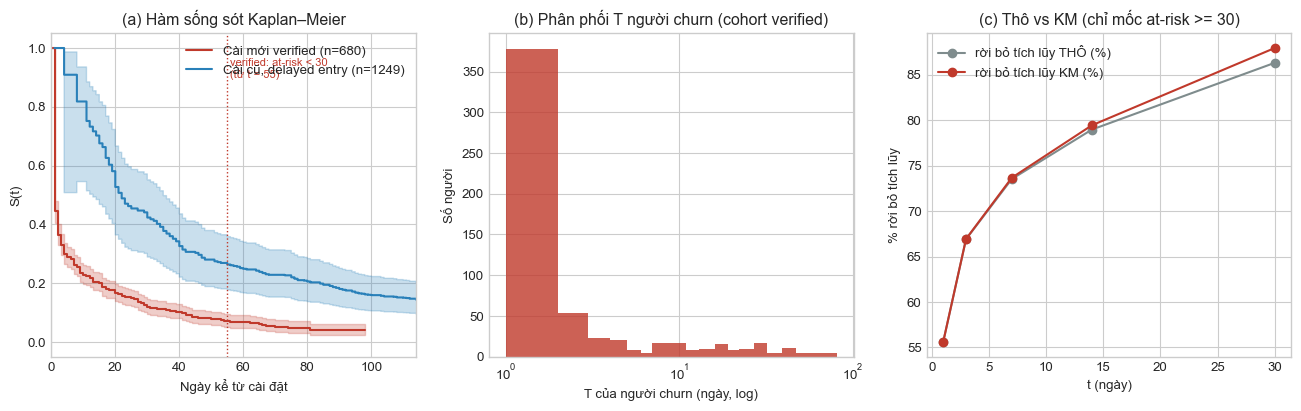

In [2]:
comp = pd.DataFrame({
    'n': [len(A), len(COH), int((A.is_new & ~A.verified_new).sum()), len(OLD)],
    'churn': [int(A.event.sum()), int(COH.event.sum()), int(A[A.is_new & ~A.verified_new].event.sum()), int(OLD.event.sum())]},
    index=['Nhóm A (tất cả có hoạt động chủ động)', 'Cài mới - verified', 'Cài mới - chưa xác minh (độ trễ > 1 ngày, không first_open)', 'Cài cũ (trước 12/06/2018)'])
comp['tỷ lệ churn (%)'] = (comp.churn / comp.n * 100).round(1)
display(comp);

# --- KM cohort verified (không cần entry) và cài cũ (có entry) ---
km_c, km_o = km(COH), km(OLD, entry=True)
def at_risk(df, t, entry=False):
    return int(((df['T'] >= t) & ((df.entry < t) if entry else True)).sum())
rows = []
for t in [1, 3, 7, 14, 30, 60, 90]:
    rows.append({'t (ngày)': t,
                 'S(t) cohort verified': round(float(km_c.predict(t)), 3), 'at-risk (verified)': at_risk(COH, t),
                 'S(t) cài cũ (entry)': round(float(km_o.predict(t)), 3), 'at-risk (cài cũ)': at_risk(OLD, t, True)})
tab_km = pd.DataFrame(rows).set_index('t (ngày)')
tab_km['verified: đáng tin (at-risk >= 30)'] = tab_km['at-risk (verified)'] >= MIN_AT_RISK
tab_km['cài cũ: đáng tin (at-risk >= 30)'] = tab_km['at-risk (cài cũ)'] >= MIN_AT_RISK
display(tab_km);
print('Lưu ý: (i) người cài cũ: at-risk ở t nhỏ rất ít (chỉ người có entry <= t); (ii) cohort verified: at-risk cạn dần ở t lớn '
      '(người cài muộn bị censor sớm). Chỉ đọc S(t) ở các mốc có at-risk >= 30.')
print(f'Trung vị KM: cohort verified = {km_c.median_survival_time_} ngày | cài cũ (có entry) = {km_o.median_survival_time_} ngày')
naive_old = KaplanMeierFitter().fit(OLD['T'], OLD.event)
print(f'Nếu BỎ entry cho người cài cũ: trung vị = {naive_old.median_survival_time_} ngày (sai do không khai báo left-truncation)')

# --- naive vs KM (cohort verified) ---
rows = []
for t in [1, 3, 7, 14, 30, 60, 90]:
    naive = ((COH.event == 1) & (COH['T'] <= t)).mean() * 100
    rows.append({'t': t, 'rời bỏ tích lũy THÔ (%)': round(naive, 2), 'rời bỏ tích lũy KM (%)': round((1 - float(km_c.predict(t))) * 100, 2)})
tab_nv = pd.DataFrame(rows).set_index('t'); tab_nv['chênh lệch (điểm %)'] = (tab_nv.iloc[:, 1] - tab_nv.iloc[:, 0]).round(2)
tab_nv['at-risk (verified)'] = [at_risk(COH, t) for t in tab_nv.index]
tab_nv['đáng tin (at-risk >= 30)'] = tab_nv['at-risk (verified)'] >= MIN_AT_RISK
display(tab_nv);

# --- Hình 4.1 ---
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
km_c.plot_survival_function(ax=ax[0], label=f'Cài mới verified (n={len(COH)})', color='#c0392b')
km_o.plot_survival_function(ax=ax[0], label=f'Cài cũ, delayed entry (n={len(OLD)})', color='#2980b9')
ax[0].set_xlim(0, 114); ax[0].set_xlabel('Ngày kể từ cài đặt'); ax[0].set_ylabel('S(t)'); ax[0].set_title('(a) Hàm sống sót Kaplan–Meier')
t_cut = next((t for t in range(1, 115) if at_risk(COH, t) < MIN_AT_RISK), None)
if t_cut: ax[0].axvline(t_cut, color='#c0392b', ls=':', lw=1); ax[0].text(t_cut + 1, .9, f'verified: at-risk < {MIN_AT_RISK}\n(từ t = {t_cut})', fontsize=8, color='#c0392b')
ch = COH[COH.event == 1]['T']
ax[1].hist(ch, bins=np.unique(np.round(np.logspace(0, np.log10(max(ch.max(), 2)), 25))), color='#c0392b', alpha=.8)
ax[1].set_xscale('log'); ax[1].set_xlabel('T của người churn (ngày, log)'); ax[1].set_ylabel('Số người'); ax[1].set_title('(b) Phân phối T người churn (cohort verified)')
tab_nv.loc[tab_nv['đáng tin (at-risk >= 30)']].iloc[:, :2].plot(ax=ax[2], marker='o', color=['#7f8c8d', '#c0392b']); ax[2].set_title('(c) Thô vs KM (chỉ mốc at-risk >= 30)')
ax[2].set_ylabel('% rời bỏ tích lũy'); ax[2].set_xlabel('t (ngày)')

day0 = (COH.seen == 0).mean() * 100
print(f'{day0:.1f}% cohort verified chỉ hoạt động đúng ngày cài đặt (seen = 0, T = 1).')
print(f'T là "số ngày lịch có mặt tính cả ngày cài" (ngày 1 = ngày cài đặt), KHÔNG phải 24 giờ đầu.')

## 4.2. Nền tảng (platform): so sánh, và kiểm tra nhiễu bởi quốc gia/thiết bị

In [3]:
# nhóm quốc gia: giữ nước có >= 30 người TRONG COHORT SO SÁNH, còn lại gộp 'Other'
# (quy tắc dựa trên cỡ mẫu, đặt trước khi xem kết quả; không chọn Top-N sau khi thấy p-value)
cnt = COH.country.fillna('Unknown').value_counts()
keep = cnt[cnt >= 30].index.tolist()
for d in (A, COH, OLD, B):
    d['country_grp'] = d.country.fillna('Unknown').where(d.country.fillna('Unknown').isin(keep), 'Other')
print('Quốc gia giữ riêng (n >= 30 trong cohort verified):', keep)

rows = [km_row(COH[COH.platform == p], p) for p in ['IOS', 'ANDROID']]
tab_pf = pd.DataFrame(rows).set_index('Nhóm'); display(tab_pf); 

ct = pd.crosstab(COH.platform, COH.event); chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
lr = logrank_test(COH[COH.platform == 'IOS']['T'], COH[COH.platform == 'ANDROID']['T'],
                  COH[COH.platform == 'IOS'].event, COH[COH.platform == 'ANDROID'].event)
print(f'Chi-square (platform x churn, cohort verified): chi2 = {chi2:.3f}, df = {dof}, p = {p_chi:.4f}')
print(f'Log-rank iOS vs Android (xử lý censoring): chi2 = {lr.test_statistic:.3f}, p = {lr.p_value:.4f}')

# Cox đơn biến có entry trên TOÀN Nhóm A (dùng cả cài cũ), và Cox hiệu chỉnh quốc gia + thiết bị trên cohort verified
def cox_hr(df, cols, entry=False):
    d = df[['T', 'event'] + ([ 'entry'] if entry else [])].copy()
    X = pd.get_dummies(df[cols], drop_first=False)
    drop = [c for c in X.columns if c.endswith(('_IOS', '_mobile', '_United States'))]   # nhóm tham chiếu
    X = X.drop(columns=drop).astype(float); d = pd.concat([d, X], axis=1)
    f = CoxPHFitter(penalizer=0.0).fit(d, 'T', 'event', entry_col='entry' if entry else None)
    s = f.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
    s.columns = ['HR', 'CI thấp', 'CI cao', 'p']; s = s.round(3); s['p'] = s['p'].map(lambda v: '<0.001' if v < 0.001 else f'{v:.3f}'); return s
print('\n--- Cox đơn biến, Nhóm A có delayed entry (tham chiếu: iOS) ---')
display(cox_hr(A, ['platform'], entry=True))
print('--- Cox hiệu chỉnh platform + device + country, Nhóm A có delayed entry ---')
adjA = cox_hr(A, ['platform', 'device_category', 'country_grp'], entry=True); display(adjA); 
print('--- Cox hiệu chỉnh platform + device + country, cohort verified (tham chiếu: iOS, mobile, US) ---')
adj = cox_hr(COH, ['platform', 'device_category', 'country_grp']); display(adj); 

print('--- Cox hiệu chỉnh platform + device, cohort verified, LOẠI Ấn Độ (platform và India gần như cộng tuyến) ---')
adj_noin = cox_hr(COH[COH.country_grp != 'India'].copy(), ['platform', 'device_category']); display(adj_noin);
Z = A[['T', 'event', 'entry']].copy(); Z['android'] = (A.platform == 'ANDROID').astype(float); Z['is_new'] = A.is_new.astype(float)
Z['android_x_new'] = Z.android * Z.is_new; Z['india'] = (A.country == 'India').astype(float); Z['tablet'] = (A.device_category == 'tablet').astype(float)
fz = CoxPHFitter().fit(Z, 'T', 'event', entry_col='entry'); inter = fz.summary.loc['android_x_new']
print(f"Tương tác Android x cài mới (Nhóm A, có entry, hiệu chỉnh India + tablet): HR = {inter['exp(coef)']:.3f}, p = {inter['p']:.4f}")

mix = pd.crosstab(COH.country_grp, COH.platform, normalize='index').mul(100).round(1)
mix['n'] = COH.country_grp.value_counts(); display(mix.rename(columns={'ANDROID': '% Android', 'IOS': '% iOS'}))

Quốc gia giữ riêng (n >= 30 trong cohort verified): ['United States', 'India']


,N,Sự kiện,Tỉ lệ churn,Trung vị (ngày),S(7),S(14),S(30),S(60)
Nhóm,,,,,,,,
IOS,256,227,88.7,1.0,0.294,0.224,0.145,0.081
ANDROID,424,394,92.9,1.0,0.245,0.194,0.107,0.061


Chi-square (platform x churn, cohort verified): chi2 = 3.126, df = 1, p = 0.0770
Log-rank iOS vs Android (xử lý censoring): chi2 = 1.487, p = 0.2226

--- Cox đơn biến, Nhóm A có delayed entry (tham chiếu: iOS) ---


,HR,CI thấp,CI cao,p
covariate,,,,
platform_ANDROID,1.264,1.145,1.396,<0.001


--- Cox hiệu chỉnh platform + device + country, Nhóm A có delayed entry ---


...

,HR,CI thấp,CI cao,p
covariate,,,,
platform_ANDROID,0.870,0.707,1.071,0.189
device_category_tablet,0.766,0.609,0.964,0.023
country_grp_India,1.390,1.094,1.764,0.007
country_grp_Other,1.124,0.938,1.348,0.205


--- Cox hiệu chỉnh platform + device, cohort verified, LOẠI Ấn Độ (platform và India gần như cộng tuyến) ---


,HR,CI thấp,CI cao,p
covariate,,,,
platform_ANDROID,0.906,0.735,1.116,0.352
device_category_tablet,0.782,0.617,0.992,0.042


Tương tác Android x cài mới (Nhóm A, có entry, hiệu chỉnh India + tablet): HR = 1.249, p = 0.0383


platform,% Android,% iOS,n
country_grp,,,
India,99.2,0.8,130
Other,63.3,36.7,270
United States,44.3,55.7,280


## 4.3. Địa lý và loại thiết bị

,N,Sự kiện,Tỉ lệ churn,Trung vị (ngày),S(7),S(14),S(30),S(60)
Nhóm,,,,,,,,
United States,280,250,89.3,1.0,0.319,0.249,0.164,0.080
Other,270,246,91.1,1.0,0.240,0.182,0.109,0.079
India,130,125,96.2,1.0,0.192,0.162,0.052,0.023


,N,Sự kiện,Tỉ lệ churn,Trung vị (ngày),S(7),S(14),S(30),S(60)
Nhóm,,,,,,,,
mobile,527,487,92.4,1.0,0.232,0.176,0.100,0.064
tablet,153,134,87.6,1.0,0.370,0.307,0.193,0.084


--- BẢNG HIỆU CHỈNH HOLM CHO 3 KIỂM ĐỊNH NHÂN KHẨU HỌC ---


,Kiểm định,Raw p-value,Holm Multiplier,Holm-adjusted p,Ý nghĩa (alpha=0.05)
0,Loại thiết bị (Mobile vs Tablet),0.0063,3,0.0188,Có
1,Quốc gia (Multivariate Log-rank),0.0087,2,0.0188,Có
2,Nền tảng (iOS vs Android),0.2226,1,0.2226,Không


Text(0.5, 0, 'Ngày kể từ cài đặt')

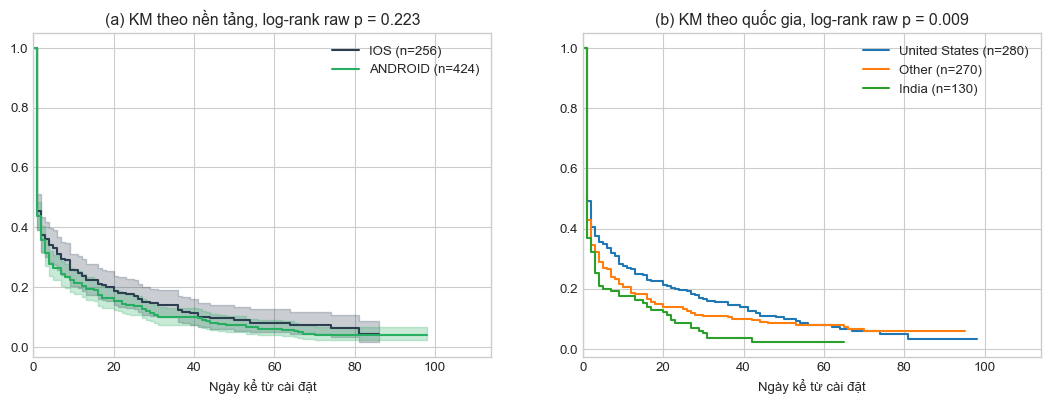

In [4]:
# 1. Log-rank theo Quốc gia
rows_ct = [km_row(COH[COH.country_grp == g], g) for g in COH.country_grp.value_counts().index]
tab_ct = pd.DataFrame(rows_ct).set_index('Nhóm'); display(tab_ct);
ct = pd.crosstab(COH.country_grp, COH.event)
chi2, p_all, dof, exp = stats.chi2_contingency(ct)
mlr = multivariate_logrank_test(COH['T'], COH.country_grp, COH.event)
p_ct = mlr.p_value

# 2. Log-rank theo Thiết bị
rows_dv = [km_row(COH[COH.device_category == g], g) for g in COH.device_category.value_counts().index]
tab_dv = pd.DataFrame(rows_dv).set_index('Nhóm'); display(tab_dv); 
lrd = logrank_test(*[COH[COH.device_category == g]['T'] for g in ['mobile', 'tablet']], *[COH[COH.device_category == g].event for g in ['mobile', 'tablet']])
p_dv = lrd.p_value

# 3. Log-rank theo Nền tảng (Platform)
lr_plat = logrank_test(*[COH[COH.platform == g]['T'] for g in ['IOS', 'ANDROID']], *[COH[COH.platform == g].event for g in ['IOS', 'ANDROID']])
p_plat = lr_plat.p_value

# Hiệu chỉnh Holm cho 3 phép thử chính (Platform, Country, Device)
tests = [
    ('Quốc gia (Multivariate Log-rank)', p_ct),
    ('Loại thiết bị (Mobile vs Tablet)', p_dv),
    ('Nền tảng (iOS vs Android)', p_plat)
]
# Sắp xếp theo raw p-value tăng dần
tests.sort(key=lambda x: x[1])

# Gọi trực tiếp hàm holm() chuẩn đã định nghĩa (có bước cummax)
raw_pvals = [t[1] for t in tests]
adj_pvals = holm(raw_pvals)

m = len(tests)
holm_rows = []
for rank, ((name, raw_p), adj_p) in enumerate(zip(tests, adj_pvals), start=1):
    holm_rows.append({
        'Kiểm định': name, 
        'Raw p-value': round(raw_p, 4), 
        'Holm Multiplier': m - rank + 1, 
        'Holm-adjusted p': round(adj_p, 4), 
        'Ý nghĩa (alpha=0.05)': 'Có' if adj_p < 0.05 else 'Không'
    })

tab_holm = pd.DataFrame(holm_rows)
print('--- BẢNG HIỆU CHỈNH HOLM CHO 3 KIỂM ĐỊNH NHÂN KHẨU HỌC ---')
display(tab_holm);

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for p, c in [('IOS', '#2c3e50'), ('ANDROID', '#27ae60')]:
    km(COH[COH.platform == p]).plot_survival_function(ax=ax[0], label=f'{p} (n={(COH.platform == p).sum()})', color=c)
ax[0].set_xlim(0, 114); ax[0].set_title(f'(a) KM theo nền tảng, log-rank raw p = {p_plat:.3f}'); ax[0].set_xlabel('Ngày kể từ cài đặt')
for g in COH.country_grp.value_counts().index:
    km(COH[COH.country_grp == g]).plot_survival_function(ax=ax[1], label=f'{g} (n={(COH.country_grp == g).sum()})', ci_show=False)
ax[1].set_xlim(0, 114); ax[1].set_title(f'(b) KM theo quốc gia, log-rank raw p = {p_ct:.3f}'); ax[1].set_xlabel('Ngày kể từ cài đặt')


## 4.4. Nhóm B (Landmark) và phân khúc mô tả


,N,Sự kiện,Tỉ lệ churn,Trung vị (ngày),S(14),S(30),S(60)
Nhóm,,,,,,,
Highly Engaged,13,6,46.2,39.0,0.755,0.551,0.413
Moderate,24,11,45.8,51.0,0.774,0.671,0.413
Low,36,30,83.3,16.0,0.601,0.213,0.053
Very Low,48,29,60.4,28.0,0.594,0.433,0.309
Dormant,8,8,100.0,16.0,0.500,0.250,0.000


Nhóm B: n = 129, churn = 84, censored = 45
S(30) theo thứ tự kỳ vọng (cao -> thấp): {'Highly Engaged': np.float64(0.551), 'Moderate': np.float64(0.671), 'Low': np.float64(0.213), 'Very Low': np.float64(0.433)}
Thứ tự S(30) có giảm dần đúng như kỳ vọng: False (nếu False: cách đặt tên/ngưỡng phân khúc chưa tách được rủi ro theo thứ bậc)
Log-rank toàn cục 5 phân khúc: chi2 = 18.281, p = 0.0011


,cặp,p thô,p Holm,"có ý nghĩa sau Holm (α=0,05)"
0,Highly Engaged vs Moderate,0.7039,1.0000,False
1,Highly Engaged vs Low,0.0206,0.1646,False
2,Highly Engaged vs Very Low,0.4052,1.0000,False
3,Highly Engaged vs Dormant,0.0510,0.3058,False
4,Moderate vs Low,0.0003,0.0028,True
5,Moderate vs Very Low,0.0957,0.4310,False
6,Moderate vs Dormant,0.0050,0.0453,True
7,Low vs Very Low,0.0230,0.1646,False
8,Low vs Dormant,0.7962,1.0000,False
9,Very Low vs Dormant,0.0862,0.4310,False


Số cặp có ý nghĩa sau Holm: 2/10
Chi-square phân khúc x churn: chi2 = 15.999, p = 0.0030; ô kỳ vọng < 5: 2/10 (kết quả chỉ mang tính tham khảo)


[None, None, None, None, None]

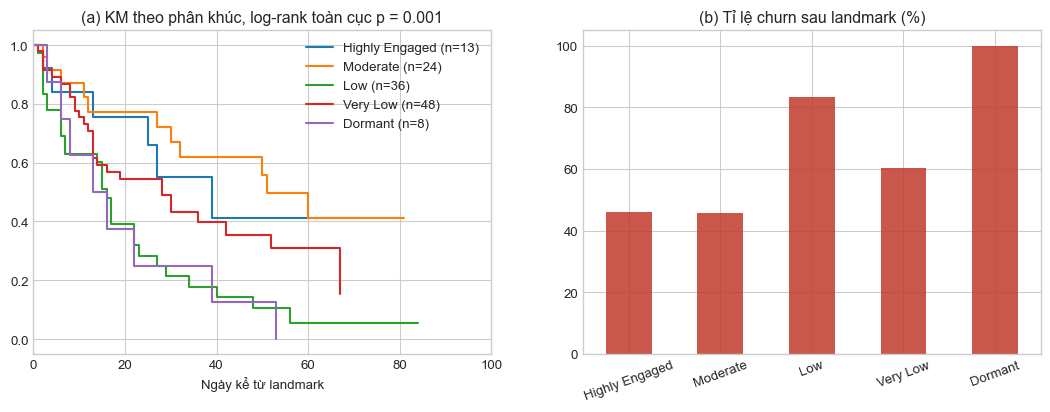

In [5]:
order = ['Highly Engaged', 'Moderate', 'Low', 'Very Low', 'Dormant'] 
rows = [km_row(B[B.engagement_segment == s], s, tcol='T_B', pts=(14, 30, 60)) for s in order]
tab_seg = pd.DataFrame(rows).set_index('Nhóm'); display(tab_seg);
print(f'Nhóm B: n = {len(B)}, churn = {int(B.event.sum())}, censored = {int((B.event == 0).sum())}')

exp_order = ['Highly Engaged', 'Moderate', 'Low', 'Very Low']
s30 = tab_seg.loc[exp_order, 'S(30)']
print('S(30) theo thứ tự kỳ vọng (cao -> thấp):', dict(s30))
print('Thứ tự S(30) có giảm dần đúng như kỳ vọng:', bool(s30.is_monotonic_decreasing), '(nếu False: cách đặt tên/ngưỡng phân khúc chưa tách được rủi ro theo thứ bậc)')
glob = multivariate_logrank_test(B.T_B, B.engagement_segment, B.event)
print(f'Log-rank toàn cục 5 phân khúc: chi2 = {glob.test_statistic:.3f}, p = {glob.p_value:.4f}')
import itertools
pairs = list(itertools.combinations(order, 2)); res = []
for a, b in pairs:
    x, y = B[B.engagement_segment == a], B[B.engagement_segment == b]
    r = logrank_test(x.T_B, y.T_B, x.event, y.event); res.append(r.p_value)
pair_df = pd.DataFrame({'cặp': [f'{a} vs {b}' for a, b in pairs], 'p thô': np.round(res, 4), 'p Holm': np.round(holm(res), 4)})
pair_df['có ý nghĩa sau Holm (α=0,05)'] = pair_df['p Holm'] < 0.05
display(pair_df);
print(f"Số cặp có ý nghĩa sau Holm: {int(pair_df['có ý nghĩa sau Holm (α=0,05)'].sum())}/{len(pair_df)}")

ct = pd.crosstab(B.engagement_segment, B.event).reindex(order)
chi2, p_seg, dof, exp = stats.chi2_contingency(ct)
print(f'Chi-square phân khúc x churn: chi2 = {chi2:.3f}, p = {p_seg:.4f}; ô kỳ vọng < 5: {(exp < 5).sum()}/{exp.size} (kết quả chỉ mang tính tham khảo)')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for s in order:
    d = B[B.engagement_segment == s]
    if len(d) >= 5: KaplanMeierFitter().fit(d.T_B, d.event, label=f'{s} (n={len(d)})').plot_survival_function(ax=ax[0], ci_show=False)
ax[0].set_xlim(0, 100); ax[0].set_xlabel('Ngày kể từ landmark'); ax[0].set_title(f'(a) KM theo phân khúc, log-rank toàn cục p = {glob.p_value:.3f}')
(tab_seg['Tỉ lệ churn']).plot.bar(ax=ax[1], color='#c0392b', alpha=.85); ax[1].set_title('(b) Tỉ lệ churn sau landmark (%)')
ax[1].set_xlabel(''); plt.setp(ax[1].get_xticklabels(), rotation=20)


## 4.5. Hành vi ngày cài đặt và độ khó level


,N,Sự kiện,Tỉ lệ churn,Trung vị (ngày),S(7),S(14),S(30),S(60)
Nhóm,,,,,,,,
Có bắt đầu level ngày cài đặt,554,506,91.3,1.0,0.268,0.209,0.126,0.071
Không bắt đầu level ngày cài đặt,126,115,91.3,1.0,0.243,0.190,0.095,0.057


Log-rank level_day0: chi2 = 0.24, p = 0.6234
Trong nhóm KHÔNG chơi level ngày cài: 50.8% chỉ hoạt động đúng 1 ngày.
--- BẢNG ĐỘ KHÓ LEVEL (CHẾ ĐỘ THƯỜNG) ---


,lượt start,lượt complete,lượt fail,user start,user complete,hoàn thành / bắt đầu (lượt),hoàn thành / bắt đầu (user)
level_number,,,,,,,
1.0,809,513,2,499,393,0.634,0.788
2.0,858,426,17,469,337,0.497,0.719
3.0,608,356,44,400,293,0.586,0.732
4.0,496,313,31,354,266,0.631,0.751
5.0,684,244,190,333,216,0.357,0.649
6.0,693,193,219,274,170,0.278,0.620
7.0,516,159,137,219,142,0.308,0.648
8.0,433,139,156,186,124,0.321,0.667
9.0,430,107,171,154,97,0.249,0.630


,User từng bắt đầu,User dừng & churn,Tỉ lệ dừng churn (%)
Level,,,
1,499,60,12.0
2,469,57,12.2
3,400,44,11.0
4,354,25,7.1
5,333,53,15.9
6,274,57,20.8
7,219,35,16.0
8,186,31,16.7
9,154,29,18.8



--- NHẬN XÉT ĐỘ KHÓ LEVEL ---
1. Điểm cổ chai (Bottlenecks): Dựa trên quy tắc tỷ lệ user hoàn thành < 50%, các level cổ chai là [27, 29].
   - Level 27: Chỉ 39.0% user bắt đầu có thể vượt qua.
   - Level 29: Chỉ 42.9% user bắt đầu có thể vượt qua.

2. Tỷ lệ rời bỏ cao nhất: Nằm ở các Level [30, 29, 27, 6].
   - Level 30: Tỷ lệ dừng cao nhất (54.1%), tuy nhiên đây có thể xem là level cuối của dữ liệu (end-of-content) thay vì do độ khó.
   - Level 29: Tỷ lệ dừng 39.7%.
   - Level 27: Tỷ lệ dừng 37.0%.
   - Level 6: Tỷ lệ dừng 20.8%.

3. Điểm bất thường ở Level 28: Dòng tiến trình từ 27 -> 29 không tuyến tính. Level 27 có 100 user bắt đầu, nhưng Level 28 tụt xuống 50 user, sau đó Level 29 lại tăng lên 63 user. Đồng thời không có ai dừng chơi ở Level 28 (0%). Đây có thể là một level đặc biệt, sự kiện phụ, hoặc có cơ chế mở khóa khác biệt.


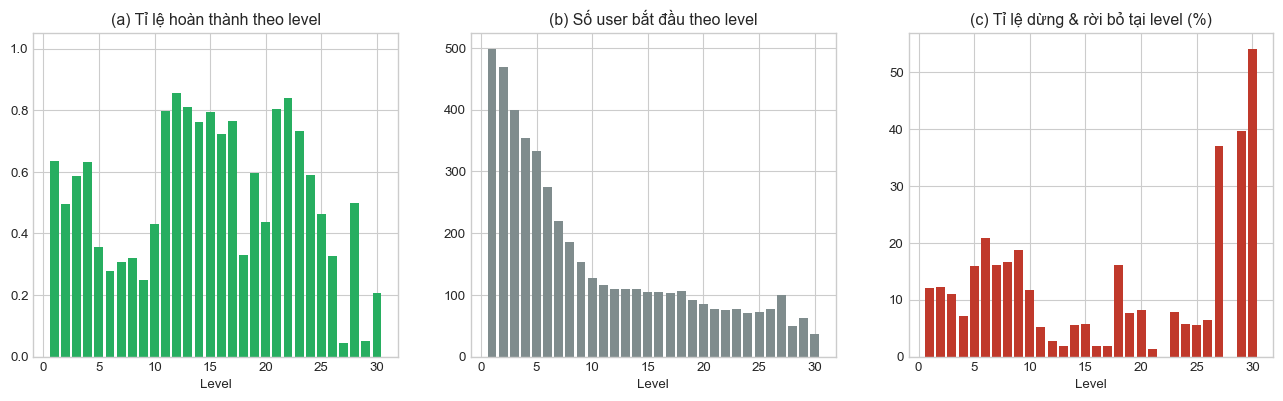

In [6]:
from PIL import TiffImagePlugin
from PIL import TiffImagePlugin
from PIL import TiffImagePlugin
lvl = pd.read_csv(os.path.join(RAW_DIR, 'fact_level.csv')).drop_duplicates()
lvl['event_date'] = pd.to_datetime(lvl.event_date.astype(str), format='%Y%m%d')
lvl['level_number'] = (lvl.level_int.fillna(lvl.level_double.round()).fillna(lvl.level_name.str.extract(r'(\d+)$')[0].astype(float)))
lvl = lvl.merge(A[['user_pseudo_id', 'install_date']], on='user_pseudo_id')
lvl['off'] = (lvl.event_date - lvl.install_date).dt.days
starts = lvl[lvl.event_name.isin(['level_start', 'level_start_quickplay'])]
d0 = set(starts[starts.off == 0].user_pseudo_id)
COH['level_day0'] = COH.user_pseudo_id.isin(d0).astype(int)

rows = [km_row(COH[COH.level_day0 == v], lab) for v, lab in [(1, 'Có bắt đầu level ngày cài đặt'), (0, 'Không bắt đầu level ngày cài đặt')]]
tab_d0 = pd.DataFrame(rows).set_index('Nhóm'); display(tab_d0);
x, y = COH[COH.level_day0 == 1], COH[COH.level_day0 == 0]
r = logrank_test(x['T'], y['T'], x.event, y.event)
print(f'Log-rank level_day0: chi2 = {r.test_statistic:.2f}, p = {r.p_value:.4g}')
sh = (COH[COH.level_day0 == 0]['T'] == 1).mean() * 100
print(f'Trong nhóm KHÔNG chơi level ngày cài: {sh:.1f}% chỉ hoạt động đúng 1 ngày.')

# ---- Độ khó level (chế độ thường), toàn Nhóm A: cả số lượt và số người duy nhất ----
nm = lvl[~lvl.event_name.str.endswith('_quickplay') & lvl.level_number.notna()]
piv_events = nm.pivot_table(index='level_number', columns='event_name', values='user_pseudo_id', aggfunc='size', fill_value=0)
piv_users  = nm.pivot_table(index='level_number', columns='event_name', values='user_pseudo_id', aggfunc='nunique', fill_value=0)

for c in ['level_start', 'level_complete', 'level_fail']:
    if c not in piv_events: piv_events[c] = 0
    if c not in piv_users:  piv_users[c] = 0

piv = pd.DataFrame({
    'lượt start': piv_events.level_start,
    'lượt complete': piv_events.level_complete,
    'lượt fail': piv_events.level_fail,
    'user start': piv_users.level_start,
    'user complete': piv_users.level_complete,
    'hoàn thành / bắt đầu (lượt)': (piv_events.level_complete / piv_events.level_start.replace(0, np.nan)).round(3),
    'hoàn thành / bắt đầu (user)': (piv_users.level_complete / piv_users.level_start.replace(0, np.nan)).round(3)
})

lv = piv[(piv['lượt start'] >= 30) & (piv.index >= 1) & (piv.index <= 30)].copy()
print('--- BẢNG ĐỘ KHÓ LEVEL (CHẾ ĐỘ THƯỜNG) ---')
display(lv.head(31)); 

# ---- Tỷ lệ dừng chân tại Level k (Drop-off Rate per Level) ----
last_started = nm[nm.event_name == 'level_start'].sort_values('event_timestamp').groupby('user_pseudo_id').level_number.last()
user_churn = A.set_index('user_pseudo_id')['event']

drop_rows = []
for k in range(1, 31):
    users_ever_k = set(nm[(nm.event_name == 'level_start') & (nm.level_number == k)].user_pseudo_id)
    if len(users_ever_k) == 0: continue
    users_last_k = set(last_started[last_started == k].index)
    users_churned_at_k = [u for u in (users_last_k & users_ever_k) if user_churn.get(u, 0) == 1]
    drop_rate = len(users_churned_at_k) / len(users_ever_k)
    drop_rows.append({'Level': k, 'User từng bắt đầu': len(users_ever_k), 'User dừng & churn': len(users_churned_at_k), 'Tỉ lệ dừng churn (%)': round(drop_rate * 100, 1)})

tab_drop = pd.DataFrame(drop_rows).set_index('Level')
display(tab_drop.head(31)); 

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(lv.index, lv['hoàn thành / bắt đầu (lượt)'], color='#27ae60'); ax[0].set_ylim(0, 1.05)
ax[0].set_title('(a) Tỉ lệ hoàn thành theo level'); ax[0].set_xlabel('Level')
ax[1].bar(lv.index, lv['user start'], color='#7f8c8d'); ax[1].set_title('(b) Số user bắt đầu theo level'); ax[1].set_xlabel('Level')
ax[2].bar(tab_drop.index, tab_drop['Tỉ lệ dừng churn (%)'], color='#c0392b'); ax[2].set_title('(c) Tỉ lệ dừng & rời bỏ tại level (%)'); ax[2].set_xlabel('Level')
# ---- In tự động nhận xét độ khó Level (sinh từ dữ liệu) ----
print("\n--- NHẬN XÉT ĐỘ KHÓ LEVEL ---")

# 1. Tìm điểm Cổ chai (Bottleneck) bằng luật động (Tỷ lệ hoàn thành user < 50%)
bottlenecks = piv[piv['hoàn thành / bắt đầu (user)'] < 0.5]
print(f"1. Điểm cổ chai (Bottlenecks): Dựa trên quy tắc tỷ lệ user hoàn thành < 50%, các level cổ chai là {bottlenecks.index.astype(int).tolist()}.")
for lvl, row in bottlenecks.iterrows():
    print(f"   - Level {int(lvl)}: Chỉ {row['hoàn thành / bắt đầu (user)']*100:.1f}% user bắt đầu có thể vượt qua.")

# 2. Tìm top các level có tỷ lệ dừng chơi & rời bỏ (churn) cao nhất
top_drops = tab_drop['Tỉ lệ dừng churn (%)'].nlargest(4)
print(f"\n2. Tỷ lệ rời bỏ cao nhất: Nằm ở các Level {top_drops.index.tolist()}.")
for lvl, rate in top_drops.items():
    if lvl == tab_drop.index.max():
        print(f"   - Level {lvl}: Tỷ lệ dừng cao nhất ({rate}%), tuy nhiên đây có thể xem là level cuối của dữ liệu (end-of-content) thay vì do độ khó.")
    else:
        print(f"   - Level {lvl}: Tỷ lệ dừng {rate}%.")

# 3. Nhận xét sự bất thường của Level 28
l27_u = piv.loc[27.0, 'user start']
l28_u = piv.loc[28.0, 'user start']
l29_u = piv.loc[29.0, 'user start']
print(f"\n3. Điểm bất thường ở Level 28: Dòng tiến trình từ 27 -> 29 không tuyến tính. Level 27 có {int(l27_u)} user bắt đầu, nhưng Level 28 tụt xuống {int(l28_u)} user, sau đó Level 29 lại tăng lên {int(l29_u)} user. Đồng thời không có ai dừng chơi ở Level 28 (0%). Đây có thể là một level đặc biệt, sự kiện phụ, hoặc có cơ chế mở khóa khác biệt.")

In [7]:
# Độ nhạy: số người bắt đầu từng cấp (chế độ thường) theo người cài mới / cài cũ
st = nm[nm.event_name == 'level_start'].merge(A[['user_pseudo_id', 'is_new']], on='user_pseudo_id')
lv_cnt = pd.DataFrame({
    'Tất cả (Nhóm A)': st.groupby('level_number').user_pseudo_id.nunique(),
    'Chỉ cài mới':     st[st.is_new == 1].groupby('level_number').user_pseudo_id.nunique(),
    'Chỉ cài cũ':      st[st.is_new == 0].groupby('level_number').user_pseudo_id.nunique(),
}).fillna(0).astype(int)
display(lv_cnt.loc[24:30])

# Với mỗi cấp k: số người bắt đầu k nhưng không có lần bắt đầu k-1 trong dữ liệu
first = st.groupby(['user_pseudo_id', 'level_number']).event_timestamp.min().unstack()
old = A.set_index('user_pseudo_id').is_new.eq(0)
rows = []
for k in range(25, 31):
    S = first[k].dropna().index
    miss = S[first.loc[S, k - 1].isna().values]
    rows.append({'cấp': k, 'người bắt đầu': len(S), 'không có cấp k-1': len(miss), 'trong đó cài cũ': int(old.reindex(miss).sum())})
display(pd.DataFrame(rows).set_index('cấp'))

,Tất cả (Nhóm A),Chỉ cài mới,Chỉ cài cũ
level_number,,,
24.0,70,50,20
25.0,72,51,21
26.0,77,52,25
27.0,100,59,41
28.0,50,30,20
29.0,63,32,31
30.0,37,22,15


,người bắt đầu,không có cấp k-1,trong đó cài cũ
cấp,,,
25,72,6,3
26,77,11,7
27,100,33,23
28,50,1,1
29,63,15,12
30,37,6,4


## 4.6. Phân phối hành vi trong 14 ngày đầu (Nhóm B)

,trung bình,trung vị,P90,max,skewness,Gini,% tổng của top 10% người,% người có giá trị = giá trị nhỏ nhất
biến,,,,,,,,
session_count,5.44,3.0,11.4,80.0,5.50,0.577,45.6,3.9
active_days,3.49,2.0,9.0,14.0,1.61,0.412,30.4,25.6
engagement_events,178.32,49.0,259.4,5709.0,7.69,0.757,66.5,1.6


Top 10% người chiếm (% tổng): {'session_count': 45.6, 'active_days': 30.4, 'engagement_events': 66.5} -> không khớp quy tắc 80/20 (Pareto) ở biến nào; Chương 2 cần bỏ hoặc giới hạn phạm vi tuyên bố 80/20.


Text(0, 0.5, 'Tỉ lệ tổng')

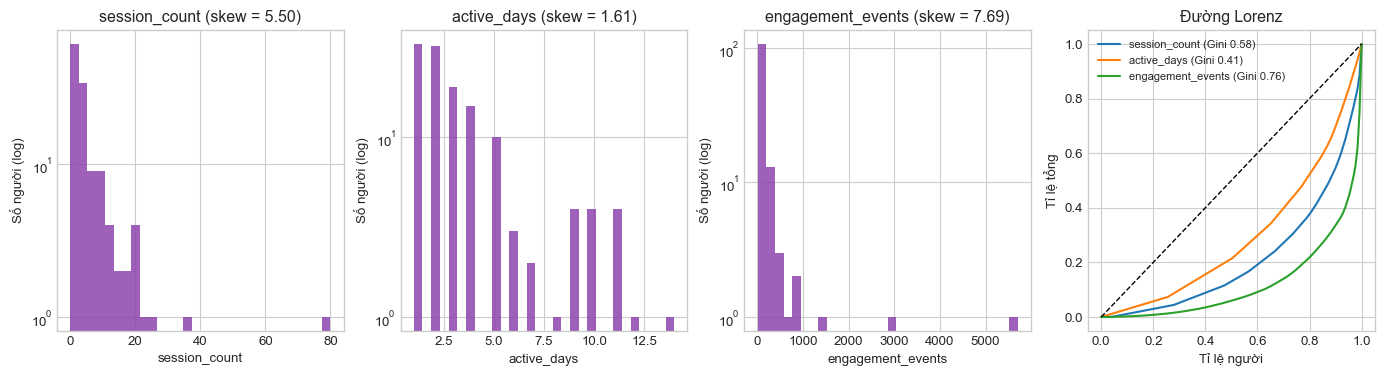

In [8]:
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); s = x.sum()
    return np.nan if s == 0 else (2 * np.sum((np.arange(1, n + 1)) * x) / (n * s)) - (n + 1) / n
metrics = ['session_count', 'active_days', 'engagement_events']
rows = []
for m in metrics:
    s = B[m]; srt = np.sort(s)[::-1]; top = max(1, int(np.ceil(len(s) * .10)))
    rows.append({'biến': m, 'trung bình': round(s.mean(), 2), 'trung vị': s.median(), 'P90': s.quantile(.9), 'max': s.max(),
                 'skewness': round(s.skew(), 2), 'Gini': round(gini(s), 3), '% tổng của top 10% người': round(srt[:top].sum() / s.sum() * 100, 1),
                 '% người có giá trị = giá trị nhỏ nhất': round((s == s.min()).mean() * 100, 1)})
tab_dist = pd.DataFrame(rows).set_index('biến'); display(tab_dist); 
print('Top 10% người chiếm (% tổng):', tab_dist['% tổng của top 10% người'].to_dict(), '-> ' +
      ('không khớp quy tắc 80/20 (Pareto) ở biến nào; Chương 2 cần bỏ hoặc giới hạn phạm vi tuyên bố 80/20.' if (tab_dist['% tổng của top 10% người'] < 80).all() else 'có biến đạt >= 80%.'))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for i, m in enumerate(metrics):
    ax[i].hist(B[m], bins=30, color='#8e44ad', alpha=.85); ax[i].set_yscale('log')
    ax[i].set_title(f'{m} (skew = {B[m].skew():.2f})'); ax[i].set_xlabel(m); ax[i].set_ylabel('Số người (log)')
for m in metrics:
    v = np.sort(B[m].values.astype(float)); cum = np.insert(np.cumsum(v) / v.sum(), 0, 0)
    ax[3].plot(np.linspace(0, 1, len(cum)), cum, label=f'{m} (Gini {gini(v):.2f})')
ax[3].plot([0, 1], [0, 1], 'k--', lw=1); ax[3].legend(fontsize=8); ax[3].set_title('Đường Lorenz'); ax[3].set_xlabel('Tỉ lệ người'); ax[3].set_ylabel('Tỉ lệ tổng')

## 4.7. Tương quan giữa các biến hành vi (Nhóm B)


,session_count,active_days,engagement_events,screen_views,distinct_screens,level_starts,level_completes,n_spend
session_count,1.00,0.92,0.82,0.82,0.59,0.79,0.65,0.46
active_days,0.92,1.00,0.69,0.74,0.53,0.65,0.53,0.41
engagement_events,0.82,0.69,1.00,0.91,0.64,0.97,0.79,0.53
screen_views,0.82,0.74,0.91,1.00,0.75,0.86,0.78,0.59
distinct_screens,0.59,0.53,0.64,0.75,1.00,0.58,0.55,0.49
level_starts,0.79,0.65,0.97,0.86,0.58,1.00,0.80,0.49
level_completes,0.65,0.53,0.79,0.78,0.55,0.80,1.00,0.51
n_spend,0.46,0.41,0.53,0.59,0.49,0.49,0.51,1.00


Cặp biến có |rho| >= 0,8: [('session_count', 'active_days', np.float64(0.92)), ('session_count', 'engagement_events', np.float64(0.82)), ('session_count', 'screen_views', np.float64(0.82)), ('engagement_events', 'screen_views', np.float64(0.91)), ('engagement_events', 'level_starts', np.float64(0.97)), ('screen_views', 'level_starts', np.float64(0.86)), ('level_starts', 'level_completes', np.float64(0.8))]


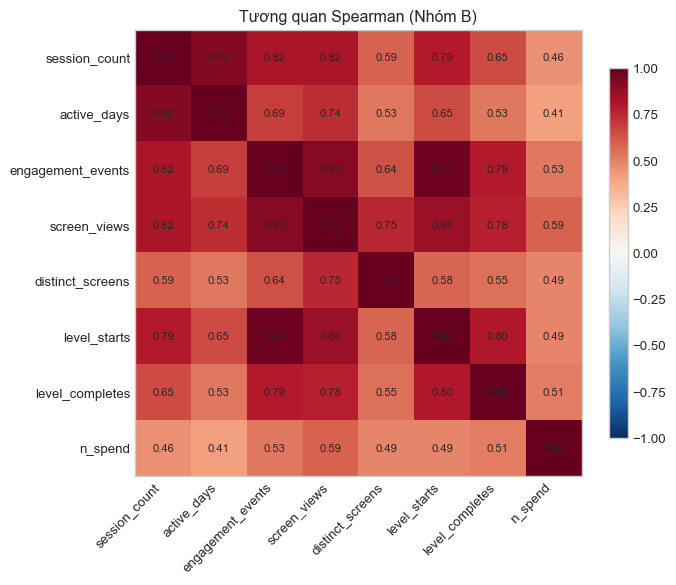

In [9]:
cand = ['session_count', 'active_days', 'engagement_events', 'screen_views', 'distinct_screens', 'level_starts', 'level_completes', 'n_spend']
sp = B[cand].corr(method='spearman').round(2); display(sp); 
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(sp.values, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_xticks(range(len(cand))); ax.set_yticks(range(len(cand)))
ax.set_xticklabels(cand, rotation=45, ha='right'); ax.set_yticklabels(cand); ax.grid(False)
for i in range(len(cand)):
    for j in range(len(cand)): ax.text(j, i, f'{sp.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, shrink=.8); ax.set_title('Tương quan Spearman (Nhóm B)')
hi = [(a, b, sp.loc[a, b]) for i, a in enumerate(cand) for b in cand[i + 1:] if abs(sp.loc[a, b]) >= 0.8]
print('Cặp biến có |rho| >= 0,8:', [(a, b, round(r, 2)) for a, b, r in hi])